# 6. Model R(2+1)D + SVM

Príznaky z video siete R(2+1)D (notebook 3, jeden vektor 512 čísel na klip)
a nad nimi rovnaký SVM a rovnaké hodnotenie ako v notebooku 4.
Od CNN-SVM sa model líši iba tým, odkiaľ pochádzajú príznaky.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from har.config import INDEX_FILE
from har.evaluation import evaluate_svm, plot_confusion, save_predictions, summary, svm_search

df = pd.read_csv(INDEX_FILE)
X = np.load("features_r21d.npy")           # (klipy, 512)

## Hodnotenie

In [2]:
pred = evaluate_svm(X, df)
save_predictions(pred, "video_cnn_svm")
summary(pred, "R(2+1)D + SVM")

,presnosť (accuracy),správne eat (recall),správne clap (recall)
R(2+1)D + SVM,94 % ± 3 %,98 % ± 4 %,91 % ± 5 %


## Chyby modelu

Matica zámen (*confusion matrix*) zo všetkých 10 delení. Riadok = skutočná trieda,
stĺpec = predpoveď modelu.
- vľavo: počet testovacích klipov (súčet cez 10 delení, každý klip je v teste viackrát),
- vpravo: % klipov danej skutočnej triedy (súčet v riadku je 100 %).

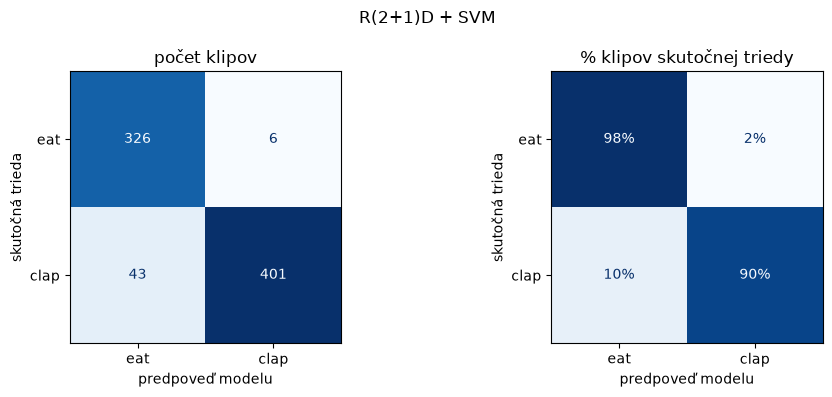

In [3]:
plot_confusion(pred, "R(2+1)D + SVM")

## Finálny model pre kameru

SVM natrénujeme na **všetkých** klipoch (parametre opäť vyberie krížová validácia)
a uložíme ho. Tento model používa skript `08_camera.py`.

In [4]:
search = svm_search(X, df.label.values, df.source.values)
print("vybrané parametre:", search.best_params_)

Path("models").mkdir(exist_ok=True)
joblib.dump(search.best_estimator_, "models/svm_r21d.joblib")

vybrané parametre: {'svm__C': 0.01, 'svm__kernel': 'linear'}


['models/svm_r21d.joblib']